# Exploratory Data Analysis (EDA) — Gas Sensor Array Drift

This notebook inspects the **UCI Gas Sensor Array Drift Dataset** (13,910 samples, 128 features from 16 chemical sensors, 6 gas classes across 10 chronological batches).

Objectives:
1. Verify data integrity (shape, missing/infinite values, class & batch distributions).
2. Quantify feature scale disparities across the 128 sensor features.
3. Visualize temporal sensor drift across Batches 1–10 both per sensor feature and in 2D PCA space.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Resolve project root reliably whether run from root or notebooks/
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "src").exists() else cwd.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import GAS_LABELS, NUM_FEATURES, load_dataset

FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\z64x\Desktop\Deeplearn project


In [2]:
df = load_dataset(
    raw_dir=PROJECT_ROOT / "data" / "raw",
    processed_path=PROJECT_ROOT / "data" / "processed" / "gas_sensor_drift.parquet",
)
feature_cols = [f"f{i}" for i in range(1, NUM_FEATURES + 1)]
X = df[feature_cols].to_numpy()

print(f"Dataset shape: {df.shape}")
print(f"Missing values (NaN): {int(df.isna().sum().sum())}")
print(f"Infinite values (Inf): {int(np.isinf(X).sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")
print("\nClass distribution:")
class_summary = (
    df["gas_name"]
    .value_counts()
    .rename_axis("gas_name")
    .to_frame("count")
)
class_summary["pct"] = (class_summary["count"] / len(df) * 100).round(2)
display(class_summary)

Dataset shape: (13910, 131)
Missing values (NaN): 0
Infinite values (Inf): 0
Duplicate rows: 0

Class distribution:


,count,pct
gas_name,,
Acetone,3009,21.63
Ethylene,2926,21.04
Ethanol,2565,18.44
Acetaldehyde,1936,13.92
Toluene,1833,13.18
Ammonia,1641,11.80


In [3]:
gas_order = [GAS_LABELS[i] for i in sorted(GAS_LABELS)]
batch_gas_ct = pd.crosstab(df["batch"], df["gas_name"])[gas_order]
batch_gas_ct["Total"] = batch_gas_ct.sum(axis=1)
batch_gas_ct.to_csv(RESULTS_DIR / "eda_batch_class_counts.csv")

print("Batch x Gas sample counts (saved to results/eda_batch_class_counts.csv):")
display(batch_gas_ct)

Batch x Gas sample counts (saved to results/eda_batch_class_counts.csv):


gas_name,Ethanol,Ethylene,Ammonia,Acetaldehyde,Acetone,Toluene,Total
batch,,,,,,,
1,90,98,83,30,70,74,445
2,164,334,100,109,532,5,1244
3,365,490,216,240,275,0,1586
4,64,43,12,30,12,0,161
5,28,40,20,46,63,0,197
6,514,574,110,29,606,467,2300
7,649,662,360,744,630,568,3613
8,30,30,40,33,143,18,294
9,61,55,100,75,78,101,470


In [4]:
feat_stats = df[feature_cols].agg(["min", "median", "mean", "std", "max"]).T
print("Summary across all 128 features (showing extreme scale differences):")
summary_of_stats = pd.DataFrame({
    "min_across_features": feat_stats.min(),
    "median_across_features": feat_stats.median(),
    "max_across_features": feat_stats.max(),
})
display(summary_of_stats)

print("\nFirst 8 features (Sensor 1: DR, |DR|, and 6 EMA features):")
display(feat_stats.iloc[:8].round(3))

Summary across all 128 features (showing extreme scale differences):


,min_across_features,median_across_features,max_across_features
min,-23660.634800,-1.902092,0.828698
median,-28.433533,4.242921,37764.263200
mean,-72.753951,5.368968,57340.104585
std,0.528660,9.633952,69844.785952
max,-0.017303,53.119525,670687.347700



First 8 features (Sensor 1: DR, |DR|, and 6 EMA features):


,min,median,mean,std,max
f1,-16757.599,19364.439,50435.066,69844.786,670687.348
f2,0.088,3.871,6.638,13.486,1339.879
f3,0.000,4.977,12.937,17.610,167.080
f4,0.000,7.251,18.744,24.899,226.619
f5,0.000,11.681,26.891,38.108,993.605
f6,-131.333,-3.339,-9.159,12.729,-0.007
f7,-227.628,-4.957,-14.402,21.305,22.202
f8,-1664.736,-14.040,-59.928,131.018,115.273


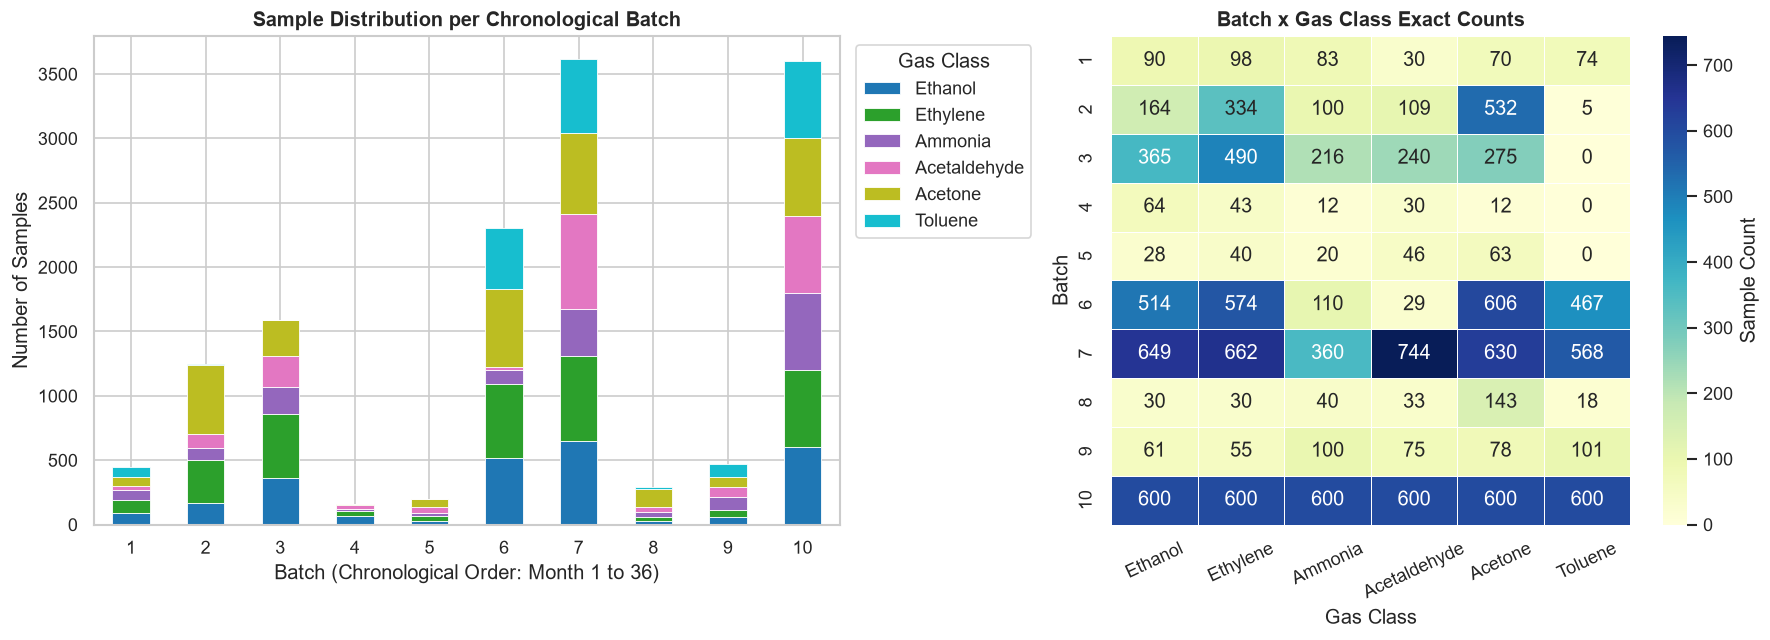

Saved figure: C:\Users\z64x\Desktop\Deeplearn project\figures\01_batch_class_distribution.png


In [5]:
counts_no_total = batch_gas_ct[gas_order]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.15, 1.0]})

# Left: Stacked bar chart
counts_no_total.plot(
    kind="bar",
    stacked=True,
    colormap="tab10",
    ax=axes[0],
    edgecolor="white",
    linewidth=0.5,
)
axes[0].set_title("Sample Distribution per Chronological Batch", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Batch (Chronological Order: Month 1 to 36)")
axes[0].set_ylabel("Number of Samples")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Gas Class", bbox_to_anchor=(1.01, 1.0), loc="upper left", frameon=True)

# Right: Exact count heatmap
sns.heatmap(
    counts_no_total,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Sample Count"},
    ax=axes[1],
)
axes[1].set_title("Batch x Gas Class Exact Counts", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Gas Class")
axes[1].set_ylabel("Batch")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
fig1_path = FIGURES_DIR / "01_batch_class_distribution.png"
fig.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig1_path}")

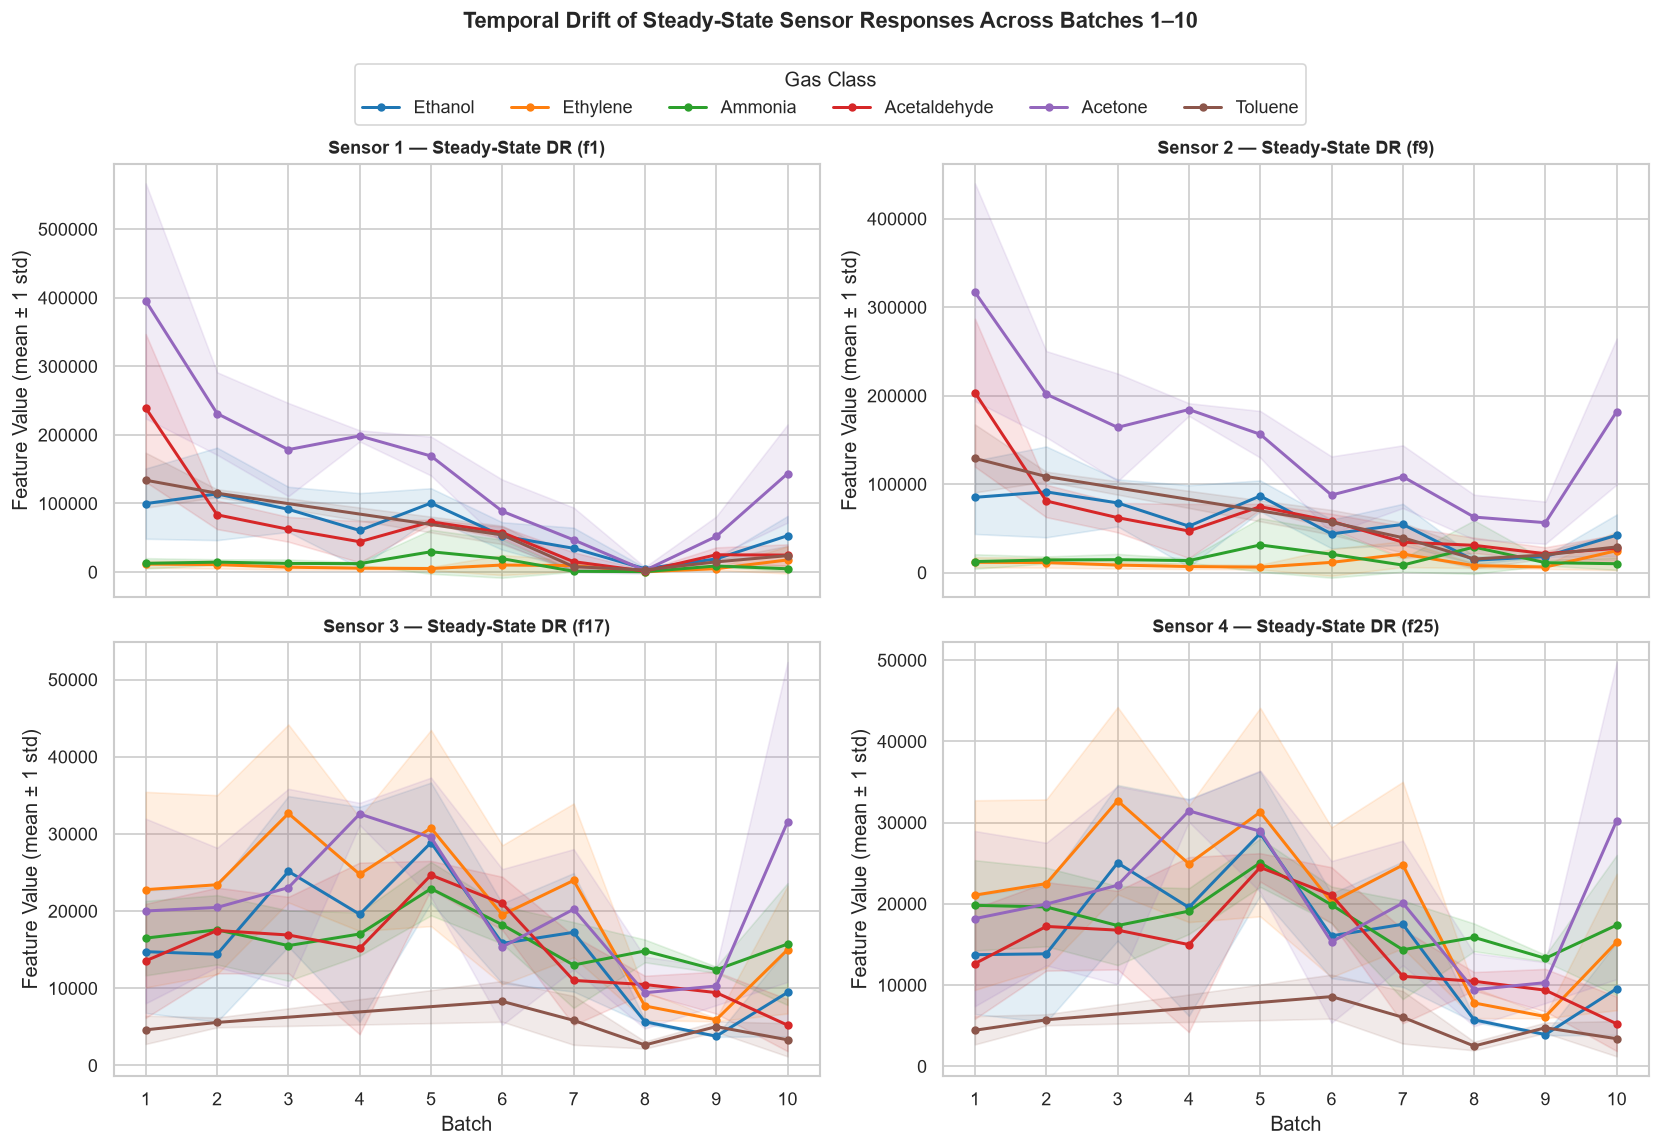

Saved figure: C:\Users\z64x\Desktop\Deeplearn project\figures\02_sensor_drift_over_batches.png


In [6]:
# Steady-state DR features for Sensors 1-4: f1, f9, f17, f25
rep_features = [
    ("f1", "Sensor 1 — Steady-State DR (f1)"),
    ("f9", "Sensor 2 — Steady-State DR (f9)"),
    ("f17", "Sensor 3 — Steady-State DR (f17)"),
    ("f25", "Sensor 4 — Steady-State DR (f25)"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
palette = sns.color_palette("tab10", n_colors=len(gas_order))

for ax, (col, title) in zip(axes.flat, rep_features):
    for gas, color in zip(gas_order, palette):
        sub = df[df["gas_name"] == gas].groupby("batch")[col]
        means = sub.mean()
        stds = sub.std().fillna(0.0)
        batches = means.index.to_numpy()
        ax.plot(batches, means.to_numpy(), marker="o", linewidth=1.8, markersize=4, label=gas, color=color)
        ax.fill_between(
            batches,
            (means - stds).to_numpy(),
            (means + stds).to_numpy(),
            alpha=0.12,
            color=color,
        )
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel("Feature Value (mean ± 1 std)")
    ax.set_xticks(range(1, 11))

axes[1, 0].set_xlabel("Batch")
axes[1, 1].set_xlabel("Batch")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.02), frameon=True, title="Gas Class")
fig.suptitle("Temporal Drift of Steady-State Sensor Responses Across Batches 1–10", fontsize=13, fontweight="bold", y=1.06)
plt.tight_layout()

fig2_path = FIGURES_DIR / "02_sensor_drift_over_batches.png"
fig.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig2_path}")

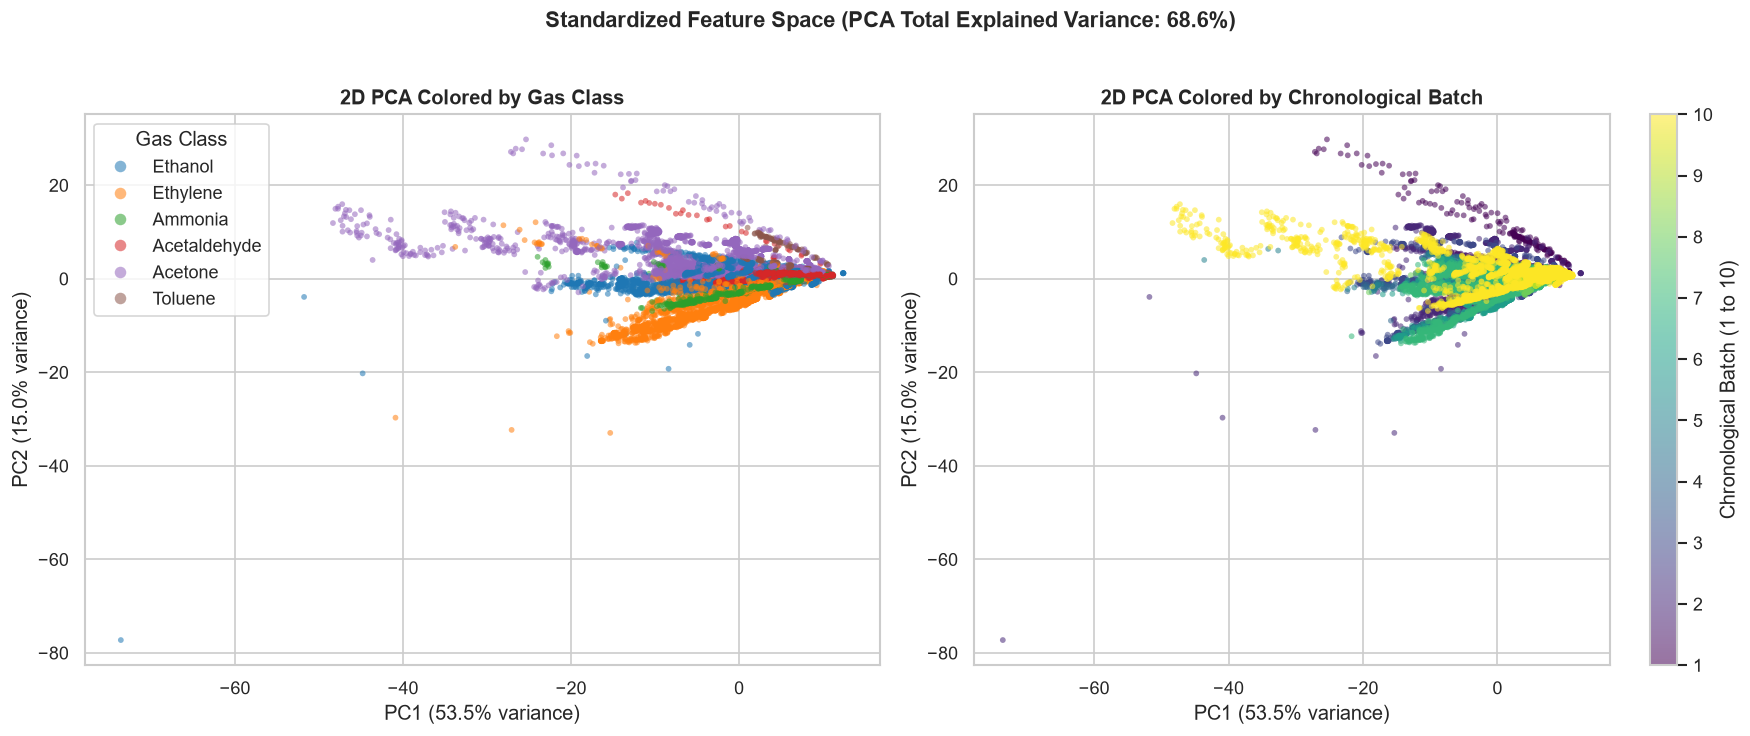

Saved figure: C:\Users\z64x\Desktop\Deeplearn project\figures\03_pca_drift_visualization.png


In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "gas_name": df["gas_name"],
    "batch": df["batch"],
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: Colored by Gas Class
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="gas_name",
    hue_order=gas_order,
    palette="tab10",
    s=12,
    alpha=0.55,
    linewidth=0,
    ax=axes[0],
)
axes[0].set_title("2D PCA Colored by Gas Class", fontsize=12, fontweight="bold")
axes[0].set_xlabel(f"PC1 ({var_exp[0]:.1f}% variance)")
axes[0].set_ylabel(f"PC2 ({var_exp[1]:.1f}% variance)")
axes[0].legend(title="Gas Class", markerscale=2, frameon=True)

# Right: Colored by Temporal Batch
sc = axes[1].scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["batch"],
    cmap="viridis",
    s=12,
    alpha=0.55,
    edgecolors="none",
)
cbar = fig.colorbar(sc, ax=axes[1], ticks=range(1, 11))
cbar.set_label("Chronological Batch (1 to 10)")
axes[1].set_title("2D PCA Colored by Chronological Batch", fontsize=12, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({var_exp[0]:.1f}% variance)")
axes[1].set_ylabel(f"PC2 ({var_exp[1]:.1f}% variance)")

fig.suptitle(
    f"Standardized Feature Space (PCA Total Explained Variance: {var_exp.sum():.1f}%)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()

fig3_path = FIGURES_DIR / "03_pca_drift_visualization.png"
fig.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig3_path}")

In [8]:
print("=== KEY EDA TAKEAWAYS ===")
print(f"1. Dataset size & integrity: {len(df):,} samples, {NUM_FEATURES} numeric features, 6 gas classes, 0 NaNs, 0 Infs.")
print(f"2. Batch imbalance: Batch sizes range from {int(batch_gas_ct['Total'].min())} (Batch {int(batch_gas_ct['Total'].idxmin())}) to {int(batch_gas_ct['Total'].max())} (Batch {int(batch_gas_ct['Total'].idxmax())}), and some batches lack certain gases (e.g. zeros in crosstab).")
print(f"3. Feature scale disparity: Raw features span [{X.min():.2f}, {X.max():.2f}], spanning multiple orders of magnitude — Z-score standardization fitted strictly on training folds is mandatory for MLP and 1D-CNN.")
print("4. Temporal sensor drift: Both steady-state sensor trajectories and 2D PCA projections reveal clear distribution shifts across Batches 1-10. Random K-Fold leaks future/past drift; chronological time-series cross-validation (train on earlier batches, test on later batches) is required for realistic evaluation.")

=== KEY EDA TAKEAWAYS ===
1. Dataset size & integrity: 13,910 samples, 128 numeric features, 6 gas classes, 0 NaNs, 0 Infs.
2. Batch imbalance: Batch sizes range from 161 (Batch 4) to 3613 (Batch 7), and some batches lack certain gases (e.g. zeros in crosstab).
3. Feature scale disparity: Raw features span [-23660.63, 670687.35], spanning multiple orders of magnitude — Z-score standardization fitted strictly on training folds is mandatory for MLP and 1D-CNN.
4. Temporal sensor drift: Both steady-state sensor trajectories and 2D PCA projections reveal clear distribution shifts across Batches 1-10. Random K-Fold leaks future/past drift; chronological time-series cross-validation (train on earlier batches, test on later batches) is required for realistic evaluation.
